# ДЗ-3. Свой A/B-тест

На семинарах С7 и С8 мы разбирали, как планировать и анализировать A/B-тесты. Теперь — самостоятельный анализ.

Представим, что вы аналитик ПРАЙМ. Команда продукта запустила акцию на 6 000 подписчиков: половина попала в тест, половина — в контроль. Эксперимент длился четыре недели, данные собраны. Продакт спрашивает: «Ну что, запускаем на всех?»

Ваша задача — разобраться, что получилось, и ответить ему. Получить `p < 0.05` и объявить эксперимент успешным недостаточно: нужно проверить, что он прошёл корректно, оценить эффект, посмотреть на побочные метрики и прикинуть, сколько ПРАЙМ на этом заработает или потеряет. Вполне может оказаться, что акцию лучше не запускать, — это тоже нормальный результат, если он следует из данных.

У каждого своя акция и свои данные: номер варианта берётся из `prime.hw3_variants`, как в хвосте семинара С7.

| Часть | Что там |
|---|---|
| **1. Подготовка** | готовый код: окружение, ваш `pilot.py`, ваш вариант |
| **2. Дизайн-документ** | как вы спланировали бы этот эксперимент |
| **3. Разминка** | задачи 1–4: дописать один аргумент |
| **4. Дописываем код** | задачи 5–8: дописать строку |
| **5. Самостоятельные задачи** | задачи 9–12: код целиком |
| **6. Отчёт** | что скажем продакту |
| **7. Итог** | ваши ответы и проверка их формата |
| **8. Исследование** | по желанию — для 9 и 10 |

Части 1–7 дают до 8 баллов, исследование — ещё до двух. Разбалловка и порядок сдачи — в [тексте задания](https://github.com/tikhomirovd/python-for-ba-hse-2026/tree/master/задания/дз-3-пилот).

JupyterLab запускается из корня `prime-monitor` командой `uv run --project pilot jupyter lab` — в окружении с HypEx, как на семинарах.

## Часть 1. Подготовка

Здесь только готовый код — запустите ячейки по порядку.

| Ячейка | Что делает |
|---|---|
| 1.1 Окружение | проверяет HypEx 1.0.7, подключается к базе, подключает ваш `src/prime/pilot.py` |
| 1.2 Ваш вариант | номер варианта; пока там `None`, он берётся из базы по вашему логину |
| 1.3 Выгрузка | загружает ваш эксперимент: 6 000 строк, одна строка — один клиент |
| 1.4 Формат ответов | служебная функция для итога |

### 1.1 Окружение

Та же ячейка, что на семинаре С8, плюс импорт пяти функций из вашего `src/prime/pilot.py`: `n_per_group` и `mde_for_n` с семинара С7, `diff_ci`, `srm_pvalue` и `cuped` с семинара С8. Дальше задачи считают ими.

Ошибка про HypEx — ноутбук запущен не в окружении `pilot/`. Ошибка про `pilot.py` — файла нет или в нём не хватает функции, см. текст задания.

In [1]:
import json
import sys
import warnings
from pathlib import Path

# Окружение pilot/ не устанавливает пакет prime: у него pandas 3, а HypEx 1.0.7
# работает только с pandas 2.2. Поэтому src/ подключаем к пути сами —
# ищем папку src/prime вверх от текущей.
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "prime").is_dir()), None)
if root is None:
    raise RuntimeError("Не нашёл src/prime. Запустите JupyterLab из корня prime-monitor:\n"
                       "uv run --project pilot jupyter lab")
sys.path.insert(0, str(root / "src"))

import hypex

if hypex.__version__ != "1.0.7":
    raise RuntimeError(f"Нужен HypEx 1.0.7, а запущен {hypex.__version__} из {sys.executable}.\n"
                       "Закройте JupyterLab и запустите из корня prime-monitor: uv run --project pilot jupyter lab")

import numpy as np
import pandas as pd
from hypex import ABTest, Matching
from hypex.dataset import Dataset, FeatureRole, InfoRole, PreTargetRole, TargetRole, TreatmentRole
from hypex.utils.enums import ABNTestMethodsEnum
from scipy import stats
from sqlalchemy import text

from prime.config import get_engine

try:
    from prime.pilot import cuped, diff_ci, mde_for_n, n_per_group, srm_pvalue
except ImportError as e:
    raise ImportError(
        f"Не получилось импортировать функции из src/prime/pilot.py: {e}\n"
        "Нужны пять функций: n_per_group и mde_for_n (семинар С7, раздел 9), "
        "diff_ci, srm_pvalue и cuped (семинар С8, раздел 8)."
    ) from None

warnings.filterwarnings("ignore")          # HypEx шумит предупреждениями pandas
pd.set_option("display.width", 160)
engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    """Выполнить запрос и вернуть DataFrame. Соединение закрывается сразу."""
    try:
        with engine.connect() as conn:
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()


def F(obj):
    """Результаты HypEx — объекты Dataset. Для pandas-операций берём .data."""
    return obj.data if hasattr(obj, "data") else obj


print("HypEx", hypex.__version__, "· pandas", pd.__version__)

HypEx 1.0.7 · pandas 2.2.3


### 1.2 Ваш вариант

Эту ячейку не меняйте: при проверке сюда подставляется номер другого варианта.

Исключение одно — сервер не отвечает (см. ячейку 1.3). Тогда впишите сюда номер своего варианта, например `VARIANT = 17`.

In [2]:
VARIANT = None   # None — номер берётся из prime.hw3_variants по вашему логину

### 1.3 Выгрузка

Одна строка — один клиент.

| Колонки | Что это |
|---|---|
| `client_id`, `grp` | клиент и его группа: `test` или `control` |
| `age`, `tenure_days`, `kyc_level`, `members`, `acquisition_channel`, `time_zone` | возраст, дней с регистрации, уровень проверки личности, сколько людей в его подписке, канал привлечения, часовой пояс |
| `spend_prev2`, `purchases_prev2`, `sessions_prev2` | оборот в партнёрских сервисах, покупки и сессии в приложении за четыре недели **позапрошлого** периода |
| `spend_prev`, `purchases_prev`, `sessions_prev` | то же за четыре недели **прямо перед** экспериментом |
| `spend`, `purchases` | оборот и покупки за четыре недели эксперимента |
| `churned`, `tickets` | ушёл ли из подписки за время эксперимента (1 — да) и сколько раз писал в поддержку |

Основная метрика у всех вариантов — `spend`, оборот в партнёрских сервисах за четыре недели, ₽.

Если сервер не отвечает, поменяйте в первой строке `False` на `True` и впишите номер варианта в ячейку 1.2: те же данные скачаются из репозитория курса. Перед сдачей верните `False`.

In [3]:
SERVER_IS_DOWN = False

RAW = ("https://raw.githubusercontent.com/tikhomirovd/python-for-ba-hse-2026/master/"
       "%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D0%B5/%D0%BF%D0%B8%D0%BB%D0%BE%D1%82/")

if VARIANT is None:
    if SERVER_IS_DOWN:
        raise RuntimeError("Без сервера номер варианта не узнать: впишите его в ячейку 1.2.")
    VARIANT = int(q("select variant from prime.hw3_variants where login = current_user").iloc[0, 0])

if SERVER_IS_DOWN:
    offers = pd.read_csv(RAW + "hw3_offers.csv.gz")
    everyone = pd.read_csv(RAW + "hw3_pilot.csv.gz")
    mine = everyone[everyone["variant"] == VARIANT].copy()
else:
    offers = q("select * from prime.hw3_offers")
    mine = q("select * from prime.hw3_pilot where variant = :v", v=VARIANT)

# Один и тот же порядок строк при любом источнике: от него зависят бутстреп и мэтчинг.
mine["client_id"] = mine["client_id"].astype(str)
mine = mine.sort_values("client_id", ignore_index=True)
offer = offers.loc[offers["variant"] == VARIANT, "offer"].iloc[0]

test = mine[mine["grp"] == "test"]
control = mine[mine["grp"] == "control"]

print(f"вариант {VARIANT}: «{offer}»")
print(len(mine), "клиентов · test", len(test), "· control", len(control))

вариант 38: «Кэшбэк 5 % на каршеринг»
6000 клиентов · test 3023 · control 2977


### 1.4 Формат ответов

Служебная ячейка: по ней итог в части 7 проверяет, что ответы записаны в нужном формате. Правильность она не проверяет. Просто запустите.

In [4]:
# Какой формат ответа ожидается в каждой задаче — человеческими словами.
EXPECTED = {
    1: "float до 3 знаков — p-значение",
    2: "float до 3 знаков — p-значение",
    3: "list [разность, нижняя граница, верхняя граница] — float до 2 знаков, рубли",
    4: "list [p t-критерия, p U-критерия] — float до 4 знаков",
    5: "list [отток: разница в п.п. до 2 знаков, p χ² до 3; обращения: разница до 3 знаков, p до 3]",
    6: "list названий метрик (str), может быть пустым",
    7: "list [θ до 3 знаков, снижение дисперсии в % до 1 знака, разность, нижняя, верхняя — до 2 знаков]",
    8: "float до 2 знаков — рубли",
    9: "list [нижняя граница, верхняя граница] — float до 2 знаков, рубли",
    10: "list [название ковариаты (str), снижение дисперсии в % — float до 1 знака]",
    11: "list [ATE, нижняя граница, верхняя граница] — float до 2 знаков, рубли",
    12: "float до 2 знаков — рубли на клиента",
}


def format_problem(n: int, answer) -> str | None:
    """Что не так с ФОРМАТОМ ответа задачи n (не с правильностью). None — всё в порядке."""

    def dec(k):   # float, у которого не больше k знаков после запятой
        return lambda x: type(x) is float and round(x, k) == x

    def items(*checks):
        return lambda a: type(a) is list and len(a) == len(checks) and all(c(x) for c, x in zip(checks, a))

    def word(x) -> bool:
        return type(x) is str and x != ""

    if answer is None:
        return "не решена: answer_N = None, или ячейка задачи не запускалась, или упала"
    checks = {
        1: dec(3), 2: dec(3),
        3: items(dec(2), dec(2), dec(2)),
        4: items(dec(4), dec(4)),
        5: items(dec(2), dec(3), dec(3), dec(3)),
        6: lambda a: type(a) is list and all(word(x) for x in a),
        7: items(dec(3), dec(1), dec(2), dec(2), dec(2)),
        8: dec(2),
        9: items(dec(2), dec(2)),
        10: items(word, dec(1)),
        11: items(dec(2), dec(2), dec(2)),
        12: dec(2),
    }
    if checks[n](answer):
        return None
    return f"нужен {EXPECTED[n]}, сейчас {answer!r} ({type(answer).__name__})"


print("проверка формата готова")

проверка формата готова


## Часть 2. Дизайн-документ

Прежде чем смотреть на результаты, зафиксируем дизайн эксперимента — так, как если бы вы планировали его сами. Если писать дизайн после итогов, гипотеза незаметно подгоняется под результат. Если вы заполнили таблицу в хвосте семинара С7, перенесите её сюда.

Ячейка ниже считает, какой эффект эксперимент такого размера вообще способен заметить. Считает ваша `mde_for_n` по обороту за прошлые четыре недели: одно сравнение, α = 0,05, мощность 80 %.

In [5]:
# Только предпериод: итогов пилота здесь нет.
n_each = len(mine) // 2
sigma = mine["spend_prev"].std()
rho = mine["spend_prev2"].corr(mine["spend_prev"])     # связь двух прошлых периодов

mde_raw = mde_for_n(sigma, n_each)
mde_cuped = mde_for_n(sigma * (1 - rho ** 2) ** 0.5, n_each)
three_pct = 0.03 * mine["spend_prev"].mean()

print(f"клиентов на группу: {n_each}, σ оборота: {sigma:.0f} ₽, ρ двух прошлых периодов: {rho:.3f}")
print(f"MDE без снижения дисперсии: {mde_raw:.0f} ₽")
print(f"MDE с CUPED:                {mde_cuped:.0f} ₽")
print(f"+3 % к среднему обороту:    {three_pct:.0f} ₽")

клиентов на группу: 3000, σ оборота: 3246 ₽, ρ двух прошлых периодов: 0.601
MDE без снижения дисперсии: 235 ₽
MDE с CUPED:                188 ₽
+3 % к среднему обороту:    95 ₽


#### ✍️ Дизайн-документ

Заполните правую колонку для своей акции — как в разделе 8 семинара С7 и на слайде 32 лекции Л7. Многоточия замените своим текстом.
| Пункт | Наш эксперимент |
|---|---|
| гипотеза: что изменится, на сколько, за какое время | Кэшбэк 5% на каршеринг увеличит средний оборот в партнёрских сервисах на 6% (около 191 ₽) на клиента за 4 недели |
| единица рандомизации и почему именно она (подпиской делятся — колонка `members`) | Владелец подписки. Участники одной подписки должны находиться в одной группе во избежание взаимного влияния |
| группы и доли | control — прежние условия; test — кэшбэк 5% на каршеринг. Случайное распределение 50/50, по 3000 клиентов на группу |
| основная метрика | Средний оборот в партнёрских сервисах на клиента за 4 недели, ₽ (`spend`) |
| метрики-стражи: что не должно ухудшиться | Доля ушедших подписчиков (`churned`), среднее количество обращений в поддержку на клиента (`tickets`) |
| α, мощность, MDE — числами из ячейки выше | α = 0,05; β = 0,20; мощность — 80%; MDE без CUPED — 235 ₽, с CUPED — 188 ₽ (5,91%) |
| поправка на множественные сравнения | Метод Холма для четырёх метрик: оборот, покупки, отток, обращения в поддержку |
| оценщик | Разность средних после CUPED по обороту предпериода (`spend_prev`), критерий Уэлча, 95% доверительный интервал |
| окно | 4 недели, без досрочной остановки |
| решающее правило: при каких результатах запускаем, дорабатываем, отказываемся | Запускаем при статистически значимом росте от 6%, отсутствии ухудшения стражей и положительном экономическом эффекте. Дорабатываем при ухудшении стражей, отрицательной экономике или недостаточной определённости результата. Отказываемся, если верхняя граница ДИ ниже целевого эффекта |

## Часть 3. Разминка

Дальше двенадцать задач. Несколько правил — один раз для всех:

- **`ЗАПОЛНИТЕ`** — место для вашего кода. Пока оно в ячейке, ячейка падает с `NameError` — так и задумано.
- Последняя строка задачи кладёт ответ в `answer_N`. Её не меняйте: по ней ответы проверяются автоматически.
- Задача не получилась — замените содержимое ячейки строкой `answer_N = None`, иначе Run All остановится на ошибке. Задачи друг от друга почти не зависят: если дальше понадобится число из пропущенной задачи, его можно пересчитать своими функциями из `pilot.py`.
- При проверке ноутбук запускается ещё раз на другом варианте. Не вписывайте результаты расчётов вручную: код должен работать с данными любого варианта, а не только вашего.
- Ноутбук не скажет, верно ли вы посчитали. Итог в части 7 проверяет только формат.

В разминке код готов, не хватает одного аргумента.

### Задача 1. SRM: сошлись ли размеры групп

Прежде чем смотреть на эффект, убедимся, что с распределением клиентов всё в порядке. Мы планировали разделить пользователей 50/50. Небольшое отклонение от этой пропорции нормально, а большой перекос — повод разобраться, что произошло с экспериментом.

Посчитайте SRM двумя способами: впишите, что передать `stats.chisquare`, и сравните со своей `srm_pvalue`. Результаты должны совпасть. Семинар С8, раздел 1.

**Ответ:** p-значение, `float` с тремя знаками — например `0.123`.

In [6]:
import pilot

sizes = mine["grp"].value_counts().sort_index()
# Проверка соответствия равным долям
srm = stats.chisquare(sizes)

print(sizes.to_dict())
print(f"scipy:    p = {srm.pvalue:.4f}")
print(f"pilot.py: p = {srm_pvalue(sizes.tolist()):.4f}")
answer_1 = round(float(srm.pvalue), 3)
answer_1

{'control': 2977, 'test': 3023}
scipy:    p = 0.5526
pilot.py: p = 0.5526


0.553

### Задача 2. Похожи ли группы до эксперимента

Если деление случайное, до эксперимента группы тратили примерно одинаково. Проверим это по обороту за прошлые четыре недели — на него акция повлиять ещё не могла.

Сравните `spend_prev` теста и контроля t-критерием Уэлча: дисперсии групп равными не считаем. Какое значение передать в `equal_var`?

**Ответ:** p-значение, `float` с тремя знаками — например `0.123`.

In [7]:
balance = stats.ttest_ind(test["spend_prev"], control["spend_prev"], equal_var=False)

print(f"spend_prev: test {test['spend_prev'].mean():.2f} ₽, control {control['spend_prev'].mean():.2f} ₽")
print(f"p = {balance.pvalue:.4f}")
answer_2 = round(float(balance.pvalue), 3)
answer_2

spend_prev: test 3180.81 ₽, control 3175.88 ₽
p = 0.9531


0.953

### Задача 3. Эффект и доверительный интервал

Главное число отчёта — насколько изменился средний оборот в тестовой группе относительно контрольной и в каких пределах может лежать эта разница. Посчитайте её своей `diff_ci`: разность test − control. Впишите первый аргумент. Семинар С8, раздел 2.

**Ответ:** `[разность, нижняя граница, верхняя граница]`, рубли с двумя знаками — например `[123.45, 12.34, 234.56]`.

In [8]:
effect = diff_ci(test["spend"], control["spend"])

print(f"test {test['spend'].mean():.2f} ₽, control {control['spend'].mean():.2f} ₽")
print(f"разность {effect['diff']:.2f} ₽, интервал {effect['lo']:.2f} … {effect['hi']:.2f}, p = {effect['p']:.4f}")
answer_3 = [round(float(effect[k]), 2) for k in ("diff", "lo", "hi")]
answer_3

test 3484.34 ₽, control 3222.01 ₽
разность 262.33 ₽, интервал 87.48 … 437.18, p = 0.0033


[262.33, 87.48, 437.18]

### Задача 4. То же в HypEx

Сверимся с HypEx: разность должна совпасть с задачей 3. Заодно посмотрим на U-критерий Манна — Уитни: он сравнивает не средние, а распределения, и на клиентов с очень большими тратами реагирует слабее.

Впишите роль колонки `grp`.

**Ответ:** `[p t-критерия, p U-критерия]`, четыре знака — например `[0.1234, 0.0123]`.

In [9]:
ds = Dataset(
    roles={"client_id": InfoRole(str), "grp": TreatmentRole(), "spend": TargetRole()},
    data=mine, default_role=InfoRole(),
)
ab = F(ABTest(additional_tests=["t-test", "u-test"]).execute(ds).resume)

print(ab.to_string(index=False))
answer_4 = [round(float(ab["TTest p-value"].iloc[0]), 4), round(float(ab["UTest p-value"].iloc[0]), 4)]
answer_4

feature group  control mean  test mean  difference  difference % TTest pass  TTest p-value UTest pass  UTest p-value
  spend  test   3222.006943 3484.33962  262.332676      8.141903         OK       0.003289         OK       0.002429


[0.0033, 0.0024]

**Вопрос 1.** Можно ли доверять разбиению на группы? Опирайтесь на p-значения задач 1 и 2. Как эффект из задачи 3 соотносится с MDE из дизайн-документа: исключает ли интервал ноль? Если t- и U-критерий в задаче 4 дали разные выводы, объясните, почему так могло получиться.

In [10]:
# Числа для ответа на вопрос 1 считайте здесь — от загруженных данных.
# Ячейка тоже выполняется на контрольном варианте: чисел руками не вписывайте.

# Проверка распределения и баланса групп
print(f"SRM: p = {srm.pvalue:.4f}")
print(f"Баланс предпериода: p = {balance.pvalue:.4f}")

# Эффект и доверительный интервал
print(f"Эффект: {effect['diff']:.2f} ₽")
print(f"95% ДИ: [{effect['lo']:.2f}; {effect['hi']:.2f}]")

# Относительный прирост оборота
growth = effect["diff"] / control["spend"].mean() * 100
print(f"Прирост оборота: {growth:.2f}%")

# Сравнение статистических критериев
print(f"t-test: p = {answer_4[0]:.4f}")
print(f"U-test: p = {answer_4[1]:.4f}")


SRM: p = 0.5526
Баланс предпериода: p = 0.9531
Эффект: 262.33 ₽
95% ДИ: [87.48; 437.18]
Прирост оборота: 8.14%
t-test: p = 0.0033
U-test: p = 0.0024


#### ✍️ Ответ на вопрос 1

По результатам SRM-теста (p = 0,5526) и проверки баланса по обороту предпериода (p = 0,9531) статистически значимых нарушений при разбиении на группы *не обнаружено*. Полученный эффект составил 262,33 ₽ (8,14%), что превышает MDE как без CUPED (235 ₽), так и с CUPED (188 ₽). Доверительный интервал [87,48; 437,18] не включает ноль, однако его нижняя граница меньше MDE. t-критерий (p = 0,0033) и U-критерий (p = 0,0024) дали одинаковые выводы о статистической значимости эффекта

## Часть 4. Дописываем код

Теперь не хватает целой строки.

### Задача 5. Метрики-стражи: отток и обращения

Рост оборота мало что значит, если акция заодно уводит клиентов из подписки или нагружает поддержку. Отток и число обращений — наши метрики-стражи. Для них подходит тот же `diff_ci`, а для оттока, раз это «да/нет», можно посчитать ещё и χ² по таблице частот, как в разделе 3 семинара С8.

Допишите строку: p-значение χ² по таблице `table` — в переменную `p_churn`.

**Ответ:** `[разница оттока в п.п., p χ², разница обращений на клиента, p обращений]` — два, три, три и три знака, например `[0.86, 0.857, 0.027, 0.743]`.

In [11]:
guards = pd.DataFrame([
    {"metric": metric, "control": control[metric].mean(), "test": test[metric].mean(),
     **diff_ci(test[metric], control[metric])}
    for metric in ("churned", "tickets")
]).set_index("metric")
print(guards.round(4).to_string())

table = pd.crosstab(mine["grp"], mine["churned"])
print(table)
# Проверяем зависимость оттока от экспериментальной группы
p_churn = stats.chi2_contingency(table).pvalue

print(f"χ² по оттоку: p = {p_churn:.4f}")
answer_5 = [round(float(guards.loc["churned", "diff"] * 100), 2), round(float(p_churn), 3),
            round(float(guards.loc["tickets", "diff"]), 3), round(float(guards.loc["tickets", "p"]), 3)]
answer_5

         control    test    diff      lo      hi       p
metric                                                  
churned   0.0296  0.0351  0.0055 -0.0034  0.0145  0.2278
tickets   0.0477  0.0509  0.0032 -0.0081  0.0145  0.5738
churned     0    1
grp               
control  2889   88
test     2917  106
χ² по оттоку: p = 0.2575


[0.55, 0.258, 0.003, 0.574]

### Задача 6. Поправка на множественные сравнения

Мы смотрим сразу на четыре метрики: оборот, покупки, отток и обращения. Чем больше сравнений, тем выше шанс, что какое-то окажется «значимым» случайно. На семинаре С8 поправку Холма считал HypEx — но там было три группы, а у нас две. Посмотрите, что HypEx напечатает про поправку теперь.

Допишите строку: p-значения с поправкой Холма — в колонку `holm`. Считаем через `statsmodels`: `multipletests(..., method="holm")` возвращает кортеж, нужный массив — второй элемент.

**Ответ:** список метрик, значимых после поправки, — например `["churned", "tickets"]`; если таких нет, `[]`.

In [12]:
from statsmodels.stats.multitest import multipletests

roles_all = {"client_id": InfoRole(str), "grp": TreatmentRole(), "spend": TargetRole(),
             "purchases": TargetRole(), "churned": TargetRole(), "tickets": TargetRole()}
res_all = ABTest(multitest_method=ABNTestMethodsEnum.holm).execute(
    Dataset(roles=roles_all, data=mine, default_role=InfoRole()))
print("HypEx о поправке:", res_all.multitest)

metrics = F(res_all.resume)[["feature", "control mean", "test mean", "difference", "TTest p-value"]].copy()
metrics["holm"] = multipletests(metrics["TTest p-value"], method="holm")[1]
metrics["rejected"] = metrics["holm"] < 0.05

print(metrics.round(4).to_string(index=False))
answer_6 = sorted(metrics.loc[metrics["rejected"], "feature"].tolist())
answer_6

HypEx о поправке: There was less than three groups or multitest method wasn't provided
  feature  control mean  test mean  difference  TTest p-value   holm  rejected
    spend     3222.0069  3484.3396    262.3327         0.0033 0.0099      True
purchases        4.8156     5.1806      0.3650         0.0007 0.0029      True
  churned        0.0296     0.0351      0.0055         0.2279 0.4558     False
  tickets        0.0477     0.0509      0.0032         0.5738 0.5738     False


['purchases', 'spend']

### Задача 7. CUPED

В задаче 3 мы посчитали эффект обычным способом. Но клиенты сильно различаются по обороту: кто-то тратит пару сотен рублей, кто-то — десятки тысяч. Попробуем CUPED и посмотрим, получится ли уменьшить дисперсию и получить более узкий доверительный интервал.

В качестве ковариаты возьмите оборот за предыдущие четыре недели, `spend_prev`. Допишите строку: примените свою `cuped(y, x)` — результат в `mine["spend_cuped"]` и `theta`. Семинар С8, разделы 5 и 8.

**Ответ:** `[θ, снижение дисперсии в %, разность, нижняя граница, верхняя граница]` — три, один и по два знака, например `[0.543, 21.0, 123.45, 12.34, 234.56]`.

In [13]:
# Ваша cuped() из pilot.py: метрика spend, ковариата spend_prev -> mine["spend_cuped"] и theta.
# Применяем CUPED
mine["spend_cuped"], theta = cuped(mine["spend"], mine["spend_prev"])


reduction = 1 - mine["spend_cuped"].var() / mine["spend"].var()

g = mine.groupby("grp")
effect_cuped = diff_ci(g.get_group("test")["spend_cuped"], g.get_group("control")["spend_cuped"])

print(f"theta = {theta:.3f}, дисперсия ниже на {reduction:.1%}")
print(f"разность {effect_cuped['diff']:.2f} ₽, интервал {effect_cuped['lo']:.2f} … {effect_cuped['hi']:.2f}")
answer_7 = [round(float(theta), 3), round(float(reduction * 100), 1),
            *[round(float(effect_cuped[k]), 2) for k in ("diff", "lo", "hi")]]
answer_7

theta = 0.641, дисперсия ниже на 36.2%
разность 259.17 ₽, интервал 119.60 … 398.74


[0.641, 36.2, 259.17, 119.6, 398.74]

### Задача 8. CUPED в HypEx

Тот же расчёт средствами HypEx. Оценка должна совпасть с задачей 7; если не совпала, ошибка в одном из двух мест — лучше найти её до отчёта.

Допишите строку: роль `pre_role` для `spend_prev` — значение метрики `spend` на один период раньше. Семинар С8, раздел 5.

**Ответ:** разность после CUPED, рубли с двумя знаками — например `123.45`.

In [14]:
# Роль для spend_prev: предпериод метрики spend, на один период назад.
pre_role = PreTargetRole(parent="spend", lag=1)

ds_cuped = Dataset(
    roles={"client_id": InfoRole(str), "grp": TreatmentRole(), "spend": TargetRole(),
           "spend_prev": pre_role},
    data=mine[["client_id", "grp", "spend", "spend_prev"]], default_role=InfoRole(),
)
res_cuped = ABTest(cuped_features={"spend": "spend_prev"}).execute(ds_cuped)

print(F(res_cuped.cuped.resume).to_string(index=False))
cuped_table = F(res_cuped.resume)
print(cuped_table.to_string(index=False))
answer_8 = round(float(cuped_table.loc[cuped_table["feature"] == "spend_cuped", "difference"].iloc[0]), 2)
answer_8

target covariate variance_reduction
 spend spend_lag              36.2%
    feature group  control mean   test mean  difference  difference % TTest pass  TTest p-value
      spend  test   3222.006943 3484.339620  262.332676      8.141903         OK       0.003289
spend_cuped  test   3223.600077 3482.770728  259.170652      8.039789         OK       0.000276


259.17

**Вопрос 2.** Что изменилось после проверки стражей и CUPED? Сработал ли какой-то страж (задача 5) и что осталось значимым после поправки (задача 6)? На сколько процентов сузился интервал после CUPED (задачи 3 и 7)? Изменилась ли сама оценка эффекта? Сравните средний оборот прошлого периода в тесте и контроле и попробуйте объяснить результат.

In [15]:
# Числа для ответа на вопрос 2 считайте здесь — от загруженных данных.
# Ячейка тоже выполняется на контрольном варианте: чисел руками не вписывайте.
# Проверка защитных метрик
print(guards.round(4).to_string())

# Значимые метрики после поправки Холма
print("Значимые метрики:", answer_6)

# Сравнение ширины доверительных интервалов
width_before = effect["hi"] - effect["lo"]
width_after = effect_cuped["hi"] - effect_cuped["lo"]

narrowing = (1 - width_after / width_before) * 100

print(f"Ширина ДИ до CUPED: {width_before:.2f} ₽")
print(f"Ширина ДИ после CUPED: {width_after:.2f} ₽")
print(f"Интервал сузился на {narrowing:.2f}%")

# Сравнение оценки эффекта
print(f"Эффект до CUPED: {effect['diff']:.2f} ₽")
print(f"Эффект после CUPED: {effect_cuped['diff']:.2f} ₽")

# Сравнение оборота предпериода
print(f"Предпериод test: {test['spend_prev'].mean():.2f} ₽")
print(f"Предпериод control: {control['spend_prev'].mean():.2f} ₽")
print(f"Разность: {test['spend_prev'].mean() - control['spend_prev'].mean():.2f} ₽")

         control    test    diff      lo      hi       p
metric                                                  
churned   0.0296  0.0351  0.0055 -0.0034  0.0145  0.2278
tickets   0.0477  0.0509  0.0032 -0.0081  0.0145  0.5738
Значимые метрики: ['purchases', 'spend']
Ширина ДИ до CUPED: 349.70 ₽
Ширина ДИ после CUPED: 279.15 ₽
Интервал сузился на 20.18%
Эффект до CUPED: 262.33 ₽
Эффект после CUPED: 259.17 ₽
Предпериод test: 3180.81 ₽
Предпериод control: 3175.88 ₽
Разность: 4.93 ₽


#### ✍️ Ответ на вопрос 2

Ни один из стражей не показал статистически значимого ухудшения: p-value для оттока составило 0,2575, а для обращений в поддержку — 0,5738. После поправки Холма статистически значимыми остались оборот (p = 0,0099) и количество покупок (p = 0,0029). Применение CUPED позволило сузить доверительный интервал на 20,18%, при этом оценка эффекта практически не изменилась — с 262,33 до 259,17 ₽. Это объясняется хорошим балансом групп в предпериоде: средний оборот в тесте составлял 3 180,81 ₽, а в контроле — 3 175,88 ₽, то есть разница была всего 4,93 ₽

## Часть 5. Самостоятельные задачи

Код пишете целиком — от `mine`, `test` и `control` до ответа. Ответ кладите обычным `float` или `str`, а не `numpy`-числом: `round(float(...), 2)`.

### Задача 9. Бутстреп

До этого мы строили доверительный интервал через нормальное приближение. Но оборот распределён неравномерно: много клиентов с небольшими тратами и немного — с очень большими. Попробуем другой способ — бутстреп: будем многократно составлять новые выборки из имеющихся наблюдений и каждый раз пересчитывать разность средних.

1. `rng = np.random.default_rng(VARIANT)` — номер варианта как seed, чтобы повторный запуск дал те же числа.
2. 2 000 раз: выберите с возвращением из оборотов теста столько значений, сколько клиентов в тесте (`rng.choice(x, size=len(x))`), затем так же из контроля, и запишите разность средних. Сначала тест, потом контроль — тогда результат воспроизводится.
3. Интервал — 2,5-й и 97,5-й перцентили этих разностей (`np.percentile`).

Сравните получившийся интервал с задачей 3. Насколько они отличаются?

**Ответ:** `[нижняя граница, верхняя граница]`, рубли с двумя знаками — например `[12.34, 234.56]`.

In [16]:
# Задача 9. 95 % интервал разности средних оборота test − control бутстрепом:
# 2 000 повторов, rng = np.random.default_rng(VARIANT), сначала тест, потом контроль.
# Генератор случайных чисел
rng = np.random.default_rng(VARIANT)

# Оборот клиентов в двух группах
x = test["spend"].to_numpy()
y = control["spend"].to_numpy()

# Список бутстреп-оценок эффекта
boot_diffs = []

for _ in range(2000):
    # Формируем выборки с возвращением
    x_sample = rng.choice(x, size=len(x), replace=True)
    y_sample = rng.choice(y, size=len(y), replace=True)

    # Сохраняем разность средних
    boot_diffs.append(x_sample.mean() - y_sample.mean())

# Рассчитываем 95% доверительный интервал
lo, hi = np.percentile(boot_diffs, [2.5, 97.5])

print(f"Бутстреп: [{lo:.2f}; {hi:.2f}]")
print(f"Нормальное приближение: [{effect['lo']:.2f}; {effect['hi']:.2f}]")

answer_9 = [round(float(lo), 2), round(float(hi), 2)]
answer_9

Бутстреп: [84.53; 441.09]
Нормальное приближение: [87.48; 437.18]


[84.53, 441.09]

### Задача 10. Какую ковариату взять

Для CUPED годится любой признак, измеренный до начала эксперимента. Чем сильнее он связан с метрикой, тем сильнее падает дисперсия: доля снижения равна ρ², квадрату корреляции. В задаче 7 мы взяли оборот за прошлые четыре недели — просто потому, что так делали на семинаре. Проверим, нет ли варианта лучше.

Посчитайте ρ² с `spend` в процентах для шести кандидатов: `"spend_prev"`, `"spend_prev2"`, `"spend_prev+spend_prev2"` (сумма двух периодов), `"purchases_prev"`, `"sessions_prev"`, `"sessions_prev2"`. Отдельно — для `purchases`, покупок за время эксперимента. Ответ — лучший из шести. Почему `purchases` брать нельзя, объясните в вопросе 3: на семинаре С8 эта ловушка уже встречалась.

**Ответ:** `[название ковариаты, ρ² в %]`, название — как в списке, процент с одним знаком, например `["purchases_prev2", 12.3]`.

In [17]:
# Задача 10. ρ² с spend (в %) для шести кандидатов из предпериода и отдельно для purchases.
# Ответ — лучший кандидат из предпериода и его ρ² в процентах.

# Формируем список кандидатов из предпериода
candidates = mine[[
    "spend_prev",
    "spend_prev2",
    "purchases_prev",
    "sessions_prev",
    "sessions_prev2"
]].copy()

# Добавляем суммарный оборот двух периодов
candidates["spend_prev+spend_prev2"] = (
    mine["spend_prev"] + mine["spend_prev2"]
)

# Рассчитываем квадрат корреляции в процентах
r2 = candidates.corrwith(mine["spend"]) ** 2 * 100

# Сортируем по убыванию
r2 = r2.sort_values(ascending=False)
print(r2.round(1))

# Отдельно проверяем покупки во время эксперимента
r2_purchases = mine["purchases"].corr(mine["spend"]) ** 2 * 100

print(f"\npurchases: {r2_purchases:.1f}%")

# Выбираем лучшую ковариату из предпериода
answer_10 = [r2.idxmax(), round(float(r2.max()), 1)]
answer_10

sessions_prev             42.9
spend_prev+spend_prev2    42.4
sessions_prev2            37.8
spend_prev                36.2
spend_prev2               31.7
purchases_prev            27.4
dtype: float64

purchases: 69.7%


['sessions_prev', 42.9]

### Задача 11. Мэтчинг на тех же данных

У нас рандомизированный эксперимент, поэтому для оценки эффекта мэтчинг, строго говоря, не нужен. Но интересно посмотреть, какой результат он даст на тех же данных: подберём каждому клиенту похожих из другой группы и сравним оценку с обычной.

Используйте `Matching(n_neighbors=5)` и признаки, измеренные до начала эксперимента: `age`, `tenure_days`, `kyc_level`, `members`, `spend_prev`, `sessions_prev`. Группу HypEx ждёт числом — заведите колонку `t`: 1 у теста, 0 у контроля. Семинар С8, раздел 6.

**Ответ:** `[ATE, нижняя граница, верхняя граница]`, рубли с двумя знаками — например `[123.45, 12.34, 234.56]`.

In [18]:
# Задача 11. Эффект на spend мэтчингом: Matching(n_neighbors=5),
# признаки age, tenure_days, kyc_level, members, spend_prev, sessions_prev.
# Ответ — ATE, нижняя и верхняя граница интервала.
# Переводим группы в числовой формат
matched = mine.assign(t=(mine["grp"] == "test").astype(int))

# Признаки для мэтчинга
feats = [
    "age", "tenure_days", "kyc_level",
    "members", "spend_prev", "sessions_prev"
]

# Назначаем роли
roles_match = {
    "client_id": InfoRole(str),
    "t": TreatmentRole(),
    "spend": TargetRole(),
    **{f: FeatureRole() for f in feats}
}

# Мэтчинг по пяти ближайшим соседям
res_match = Matching(n_neighbors=5).execute(
    Dataset(
        roles=roles_match,
        data=matched,
        default_role=InfoRole()
    )
)

match_table = F(res_match.resume)
print(match_table.to_string())
# Извлекаем ATE и границы доверительного интервала
ate = match_table.loc["ATE"]

answer_11 = [
    round(float(ate["Effect Size"]), 2),
    round(float(ate["CI Lower"]), 2),
    round(float(ate["CI Upper"]), 2)
]

answer_11


     Effect Size  Standard Error  P-value  CI Lower  CI Upper outcome
ATT       234.40           75.50      0.0     86.42    382.38   spend
ATC       295.35           75.47      0.0    147.42    443.27   spend
ATE       264.64           72.97      0.0    121.62    407.66   spend


[264.64, 121.62, 407.66]

### Задача 12. Что это в деньгах

Продакта интересует не p-значение, а деньги. Точных ставок в базе нет, поэтому берём допущения — они уже стоят в ячейке, их не меняйте.

Посчитайте результат акции на одного клиента за четыре недели: комиссия с прироста оборота (эффект с CUPED из задачи 7 × `COMMISSION`) минус дополнительные обращения (разница из задачи 5 × `TICKET_COST`) минус дополнительный отток (разница из задачи 5 × `CHURN_COST`). Если обращений или оттока в тесте меньше, знак поменяется сам. Нужные числа можно взять из задач 5 и 7 или пересчитать здесь же своими `cuped` и `diff_ci`. Напечатайте все слагаемые и итог.

**Ответ:** рубли на клиента с двумя знаками — например `-1.23`.

In [19]:
# Задача 12. Результат акции в рублях на клиента за 4 недели.
# Допущения — не меняйте их.
COMMISSION = 0.015    # комиссия ПРАЙМ с оборота в партнёрских сервисах
TICKET_COST = 150     # стоимость одного обращения в поддержку, ₽
CHURN_COST = 750      # потеря от ушедшего подписчика: три месяца «Базового», ₽
# Дополнительный доход от прироста оборота
revenue = effect_cuped["diff"] * COMMISSION

# Дополнительные расходы на поддержку
ticket_expense = guards.loc["tickets", "diff"] * TICKET_COST

# Дополнительные потери от оттока
churn_expense = guards.loc["churned", "diff"] * CHURN_COST

# Итоговый финансовый результат
profit = revenue - ticket_expense - churn_expense

print(f"Доход от комиссии: {revenue:.2f} ₽")
print(f"Расходы на поддержку: {ticket_expense:.2f} ₽")
print(f"Потери от оттока: {churn_expense:.2f} ₽")
print(f"Итог на клиента: {profit:.2f} ₽")

answer_12 = round(float(profit), 2)

answer_12

Доход от комиссии: 3.89 ₽
Расходы на поддержку: 0.49 ₽
Потери от оттока: 4.13 ₽
Итог на клиента: -0.73 ₽


-0.73

**Вопрос 3.** Какой оценке эффекта вы доверяете больше всего? Сравните ширину интервалов из задач 3, 7, 9 и 11 и объясните разницу. Почему `purchases` из задачи 10 нельзя брать ковариатой, хотя ρ² у неё самый большой? Окупается ли акция при допущениях задачи 12 и чего в этом расчёте не хватает?

In [20]:
# Числа для ответа на вопрос 3 считайте здесь — от загруженных данных.
# Ячейка тоже выполняется на контрольном варианте: чисел руками не вписывайте.
# Сравниваем доверительные интервалы
comparison = pd.DataFrame([
    ["Разность средних", *answer_3],
    ["CUPED", *answer_7[2:]],
    ["Бутстреп", effect["diff"], *answer_9],
    ["Мэтчинг", *answer_11]
], columns=["Метод", "Эффект", "Нижняя граница", "Верхняя граница"])

comparison["Ширина ДИ"] = (
    comparison["Верхняя граница"] - comparison["Нижняя граница"]
)

print(comparison.round(2).to_string(index=False))

# Потенциальное снижение дисперсии
print(f"\nЛучшая ковариата: {answer_10[0]}, {answer_10[1]}%")
print(f"Покупки во время эксперимента: {r2_purchases:.1f}%")

# Экономика акции
print(f"\nФинансовый результат: {answer_12:.2f} ₽ на клиента")


           Метод  Эффект  Нижняя граница  Верхняя граница  Ширина ДИ
Разность средних  262.33           87.48           437.18     349.70
           CUPED  259.17          119.60           398.74     279.14
        Бутстреп  262.33           84.53           441.09     356.56
         Мэтчинг  264.64          121.62           407.66     286.04

Лучшая ковариата: sessions_prev, 42.9%
Покупки во время эксперимента: 69.7%

Финансовый результат: -0.73 ₽ на клиента


#### ✍️ Ответ на вопрос 3

Для оценки эффекта я бы выбрала CUPED, поскольку этот метод даёт наиболее узкий доверительный интервал (279,14 ₽ против 349,70 ₽ у разности средних, 356,56 ₽ у бутстрепа и 286,04 ₽ у мэтчинга), а оценки эффекта всех методов близки. Лучшей ковариатой оказалась sessions_prev, позволяющая снизить дисперсию на 42,9%. Использовать purchases, несмотря на потенциальное снижение дисперсии на 69,7%, нельзя, поскольку количество покупок измеряется во время эксперимента и может зависеть от самой акции. Несмотря на статистически значимый рост оборота, расчётный финансовый результат составляет −0,73 ₽ на клиента, причём в расчёте не учтены расходы на выплату кэшбэка и неопределённость финансовой оценки, поэтому акцию целесообразно доработать, а не масштабировать.

## Часть 6. Отчёт: что скажем продакту?

Представьте, что продакт написал вам в чат: «Ну что там с экспериментом? Запускаем на всех?»

Результаты всех проверок у вас есть, теперь их нужно собрать в одно решение. Напишите короткий отчёт на четыре абзаца. Не пересказывайте каждую задачу и не объясняйте, что такое CUPED: продакту важно понять, какой эффект получился, насколько мы в нём уверены, какие есть риски и что делать дальше. Числа — из ноутбука, эффект — с интервалом.

Можно рекомендовать запуск, доработку с повторным экспериментом или отказ от акции. Главное — чтобы рекомендация следовала из ваших расчётов и решающего правила из дизайн-документа. Образец — раздел 7 семинара С8.

#### ✍️ Отчёт продакту

Что проверяли: влияние кэшбэка 5% на каршеринг на оборот клиентов в партнёрских сервисах. Эксперимент проводился в течение четырёх недель на 6 000 клиентах с распределением на тестовую и контрольную группы в пропорции 50/50. Целевой прирост оборота составлял 6%.

Что получилось: после применения CUPED прирост среднего оборота составил 259,17 ₽ (8,04%) на клиента при 95% доверительном интервале [119,60; 398,74] ₽. После поправки Холма статистически значимыми остались оборот (p = 0,0099) и количество покупок (p = 0,0029) в анализе без CUPED. Статистически значимого ухудшения защитных метрик не обнаружено.

Какие остались вопросы: несмотря на рост оборота, отток увеличился на 0,55 п. п., а количество обращений — на 0,0032 на клиента. По точечной оценке финансовый результат составил −0,73 ₽ на клиента без учёта расходов на выплату кэшбэка. Необходимо дополнительно оценить неопределённость финансового результата и причины увеличения оттока.

Что рекомендуем: доработать акцию и не масштабировать её в текущем виде. Несмотря на достижение целевого прироста по точечной оценке (8,04% против 6%), положительный финансовый результат не достигнут. Рекомендуется пересмотреть условия кэшбэка, проанализировать причины оттока и провести повторный эксперимент.

## Часть 7. Итог

Готовая ячейка: печатает ваши ответы и проверяет их формат, но не правильность. Последняя строка служебная — по ней ответы сверяются автоматически. Посмотрите на вывод перед сдачей.

In [21]:
def typed(x):
    """Для служебной строки: всё, кроме list/dict/str/int/float/bool/None, помечаем типом."""
    if type(x) is dict:
        return {str(key): typed(value) for key, value in x.items()}
    if type(x) is list:
        return [typed(value) for value in x]
    if x is None or type(x) in (bool, int, float, str):
        return x
    return f"<{type(x).__name__}> {x!r}"


answers = {n: globals().get(f"answer_{n}") for n in range(1, 13)}
formats = {n: format_problem(n, answer) for n, answer in answers.items()}

for n, answer in answers.items():
    print(f"задача {n:>2}: {answer!r}")
    print("    ✅ формат в порядке" if formats[n] is None else f"    ❌ {formats[n]}")

print("\nНе забудьте текст: дизайн-документ, ответы на вопросы 1–3 и отчёт продакту.")
print("\n--- служебная строка, не удаляйте ---")
print("HW3_ANSWERS=" + json.dumps(
    {"variant": VARIANT, "answers": typed(answers), "format": formats}, ensure_ascii=False
))

задача  1: 0.553
    ✅ формат в порядке
задача  2: 0.953
    ✅ формат в порядке
задача  3: [262.33, 87.48, 437.18]
    ✅ формат в порядке
задача  4: [0.0033, 0.0024]
    ✅ формат в порядке
задача  5: [0.55, 0.258, 0.003, 0.574]
    ✅ формат в порядке
задача  6: ['purchases', 'spend']
    ✅ формат в порядке
задача  7: [0.641, 36.2, 259.17, 119.6, 398.74]
    ✅ формат в порядке
задача  8: 259.17
    ✅ формат в порядке
задача  9: [84.53, 441.09]
    ✅ формат в порядке
задача 10: ['sessions_prev', 42.9]
    ✅ формат в порядке
задача 11: [264.64, 121.62, 407.66]
    ✅ формат в порядке
задача 12: -0.73
    ✅ формат в порядке

Не забудьте текст: дизайн-документ, ответы на вопросы 1–3 и отчёт продакту.

--- служебная строка, не удаляйте ---
HW3_ANSWERS={"variant": 38, "answers": {"1": 0.553, "2": 0.953, "3": [262.33, 87.48, 437.18], "4": [0.0033, 0.0024], "5": [0.55, 0.258, 0.003, 0.574], "6": ["purchases", "spend"], "7": [0.641, 36.2, 259.17, 119.6, 398.74], "8": 259.17, "9": [84.53, 441.09],

## Часть 8. Исследование — по желанию

Это возможность попробовать небольшое настоящее исследование, а не решить ещё несколько задач: готового формата ответа и заготовок нет, что считать — решаете вы. Каждая часть даёт до 1 балла сверх восьми и засчитывается, если основная часть набрала не меньше 15 баллов из 20.

| Каждая часть оценивается так | Балл |
|---|---|
| числа верные и получены кодом в ноутбуке | 0,4 |
| вывод следует из чисел, и названо, чего ваш расчёт **не** доказывает | 0,3 |
| код выполняется целиком, в том числе на контрольном варианте | 0,2 |
| изложено по схеме: вопрос → как проверяли → что получилось → что это значит | 0,1 |

Всё считайте от `mine`, случайность заводите через `np.random.default_rng(VARIANT)`. Текст вывода, как и везде, пишете сами.

### Исследование А. Без рандомизации

Представьте, что эксперимента не было: акцию просто показали в приложении, и увидели её только активные клиенты. Продакт сравнил их со всеми остальными и получил огромный эффект. В жизни узнать, насколько он завышен, нельзя. А у вас есть рандомизированные данные и правильный ответ можно посчитать — значит, можно проверить, насколько наблюдательные данные искажают оценку и помогает ли мэтчинг.

1. Соберите «наблюдательные» данные: из теста — только клиентов с `sessions_prev` не ниже медианы по вашему варианту, из контроля — всех.
2. Посчитайте наивную разность средних `spend`.
3. Оцените эффект мэтчингом по признакам задачи 11. Здесь нужен ATT — эффект на тех, кто акцию увидел.
4. Посчитайте эталон: разность между активными из теста и активными из контроля. Эту оценку даёт рандомизация.
5. Уберите `sessions_prev` из признаков мэтчинга и повторите. Что изменилось и почему?
6. Когда мэтчингу можно доверять — и чего ваш расчёт не доказывает?

Семинар С8, раздел 6; [слайды 22–27 Л8](../../08-анализ-пилота/лекция/Л8-слайды.pdf).




Представим, что акция была показана только активным клиентам. В этом случае тестовая и контрольная группы изначально различаются, поэтому обычная разность средних может дать смещённую оценку.

Нам нужно получить четыре оценки:
- Наивная разность средних.
- ATT после мэтчинга по всем шести признакам.
- Эталонная оценка — сравнение активных клиентов теста и контроля.
- ATT после мэтчинга без sessions_prev.
Последний расчёт покажет, насколько важно учитывать признак, по которому мы отбирали активных клиентов.

In [22]:
# 1. Определяем активных клиентов
median_sessions = mine["sessions_prev"].median()

active_test = mine[
    (mine["grp"] == "test") &
    (mine["sessions_prev"] >= median_sessions)
]

active_control = mine[
    (mine["grp"] == "control") &
    (mine["sessions_prev"] >= median_sessions)
]

all_control = mine[mine["grp"] == "control"]

# Формируем наблюдательные данные
observed = pd.concat(
    [active_test, all_control], ignore_index=True
)

observed["t"] = (observed["grp"] == "test").astype(int)

print(f"Медиана сессий: {median_sessions}")
print(f"Активных клиентов теста: {len(active_test)}")
print(f"Активных клиентов контроля: {len(active_control)}")


Медиана сессий: 15.0
Активных клиентов теста: 1546
Активных клиентов контроля: 1519


Вопрос: как отбор клиентов по активности влияет на сопоставимость экспериментальных групп?

Как проверяли: рассчитали медианное количество сессий за предпериод (sessions_prev) и отобрали клиентов с активностью не ниже медианы.

Что получилось: медиана составила 15 сессий. В тестовой группе оказалось 1 546 активных клиентов, в контрольной — 1 519.

Что это значит: мы выделили сопоставимые по критерию отбора подгруппы активных клиентов. Сравнение активных клиентов теста со всей контрольной группой может привести к смещению оценки эффекта из-за различий в исходной активности.

In [23]:

# 2. Наивная оценка эффекта
naive = active_test["spend"].mean() - all_control["spend"].mean()

# 3. Мэтчинг по всем признакам
feats_a = [
    "age", "tenure_days", "kyc_level",
    "members", "spend_prev", "sessions_prev"
]

def matching_att(data, features):
    roles = {
        "client_id": InfoRole(str),
        "t": TreatmentRole(),
        "spend": TargetRole(),
        **{f: FeatureRole() for f in features}
    }

    result = Matching(n_neighbors=5).execute(
        Dataset(
            roles=roles,
            data=data.copy(),
            default_role=InfoRole()
        )
    )

    return F(result.resume).loc["ATT", "Effect Size"]

att_full = matching_att(observed, feats_a)

# 4. Эталонная оценка на рандомизированных данных
benchmark = (
    active_test["spend"].mean() -
    active_control["spend"].mean()
)

# 5. Мэтчинг без sessions_prev
feats_short = [
    f for f in feats_a if f != "sessions_prev"
]

att_short = matching_att(observed, feats_short)

# 6. Сравнение результатов
research_a = pd.DataFrame({
    "Метод": [
        "Наивная оценка",
        "Мэтчинг по всем признакам",
        "Эталон (рандомизация)",
        "Мэтчинг без sessions_prev"
    ],
    "Эффект, ₽": [
        naive, att_full, benchmark, att_short
    ]
})

research_a["Отклонение от эталона, ₽"] = (
    research_a["Эффект, ₽"] - benchmark
)

print(research_a.round(2).to_string(index=False))

                    Метод  Эффект, ₽  Отклонение от эталона, ₽
           Наивная оценка    1728.81                   1376.72
Мэтчинг по всем признакам     372.25                     20.16
    Эталон (рандомизация)     352.09                      0.00
Мэтчинг без sessions_prev     920.61                    568.52


Вопрос: насколько отсутствие рандомизации искажает оценку эффекта акции и позволяет ли мэтчинг уменьшить это смещение?

Как проверяли: сравнили наивную оценку, мэтчинг по всем шести признакам и мэтчинг без sessions_prev с эталонной оценкой, полученной на рандомизированных данных среди активных клиентов.

Что получилось: наивная оценка составила 1 728,81 ₽ при эталонном эффекте 352,09 ₽. Мэтчинг по всем признакам сократил отклонение от эталона с 1 376,72 до 20,16 ₽. При исключении sessions_prev отклонение увеличилось до 568,52 ₽.

Что это значит: отсутствие рандомизации привело к существенному завышению оценки эффекта. Мэтчинг позволил значительно сократить смещение, однако его результат сильно зависит от выбора признаков. Исключение активности предпериода, по которой проводился отбор клиентов, заметно ухудшило точность оценки. При этом близость к эталону не гарантирует полного устранения смещения.

#### ✍️ Исследование А

Вопрос: можно ли достоверно оценить эффект акции без рандомизации с помощью мэтчинга?

Как проверяли: искусственно нарушили рандомизацию, оставив в тесте только активных клиентов, и сравнили три способа оценки эффекта с эталоном.

Что получилось: наивная оценка превысила эталонную почти в пять раз (1 728,81 ₽ против 352,09 ₽). Мэтчинг по всем признакам сократил отклонение до 20,16 ₽, однако при исключении sessions_prev отклонение увеличилось до 568,52 ₽.

Что это значит: мэтчинг позволяет существенно уменьшить смещение оценки при отсутствии рандомизации, но его эффективность зависит от полноты и качества выбранных признаков. В нашем случае рандомизированный эксперимент остаётся более надёжным способом оценки причинно-следственного эффекта.

### Исследование Б. Сколько клиентов было нужно

В дизайн-документе вы посчитали MDE по формуле. Формула опирается на нормальное приближение, а у оборота тяжёлый хвост. Проверьте её симуляцией, как в разделе 5 семинара С7, и ответьте: сколько клиентов нужно, чтобы заметить рост оборота на 3 %?

1. Возьмите оборот контрольной группы — эффекта там нет.
2. Для нескольких размеров группы n (например, 1 000, 3 000, 10 000, 20 000, 40 000) 500 раз: выберите с возвращением 2n значений, к первой половине прибавьте эффект — 3 % от среднего оборота контроля — и сравните половины t-критерием Уэлча. Доля отвержений при α = 0,05 — это мощность.
3. Повторите для оборота после CUPED. Сначала посчитайте скорректированный оборот для каждого клиента контроля (θ по контрольной группе, ковариата — `spend_prev`), а потом выбирайте с возвращением уже его. Если выбирать `spend` и `spend_prev` по отдельности, связь между ними пропадёт, и CUPED ничего не даст.
4. Сравните с формулой мощности из семинара С7 (★3).
5. С какого n мощность доходит до 80 % без CUPED и с ним? Хватило бы вашего эксперимента? Где симуляция расходится с формулой и почему?

In [24]:
rng = np.random.default_rng(VARIANT)

# Берём данные контрольной группы
y = control["spend"].to_numpy()

# Рассчитываем CUPED только на контрольной группе
y_cuped, theta_b = cuped(
    control["spend"],
    control["spend_prev"]
)

y_cuped = y_cuped.to_numpy()

# Целевой эффект — 3% среднего оборота
delta = y.mean() * 0.03

alpha = 0.05
n_sim = 500
sizes_b = [1000, 3000, 10000, 20000, 40000]

# Мощность через симуляцию
def simulated_power(values, n, delta):
    rejected = 0

    for _ in range(n_sim):
        sample = rng.choice(values, size=2*n, replace=True)

        t = sample[:n] + delta
        c = sample[n:]

        p = stats.ttest_ind(t, c, equal_var=False).pvalue
        rejected += p < alpha

    return rejected / n_sim

# Теоретическая мощность
def theoretical_power(values, n, delta):
    sigma = values.std(ddof=1)
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    shift = delta / (sigma * np.sqrt(2 / n))

    return (
        stats.norm.sf(z_alpha - shift)
        + stats.norm.cdf(-z_alpha - shift)
    )

# Сравниваем результаты
research_b = pd.DataFrame([
    {
        "n": n,
        "Симуляция без CUPED": simulated_power(y, n, delta),
        "Формула без CUPED": theoretical_power(y, n, delta),
        "Симуляция с CUPED": simulated_power(y_cuped, n, delta),
        "Формула с CUPED": theoretical_power(y_cuped, n, delta)
    }
    for n in sizes_b
])

print(f"Целевой эффект: {delta:.2f} ₽")
print(research_b.round(3).to_string(index=False))

# Необходимый размер группы по формуле
print("\nНеобходимо клиентов на группу:")

print("Без CUPED:", n_per_group(y.std(ddof=1), delta))
print("С CUPED:", n_per_group(y_cuped.std(ddof=1), delta))

Целевой эффект: 96.66 ₽
    n  Симуляция без CUPED  Формула без CUPED  Симуляция с CUPED  Формула с CUPED
 1000                0.118              0.099              0.142            0.129
 3000                0.188              0.202              0.296            0.292
10000                0.532              0.534              0.708            0.731
20000                0.810              0.824              0.948            0.954
40000                0.990              0.983              1.000            0.999

Необходимо клиентов на группу:
Без CUPED: 18762
С CUPED: 11830


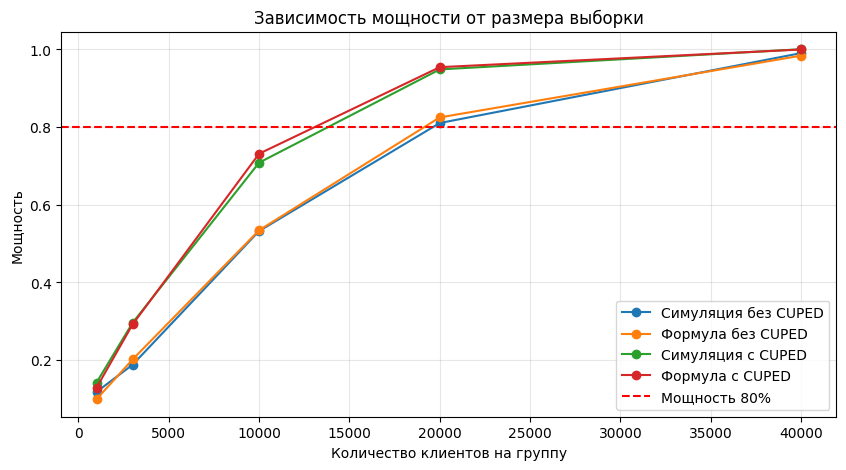

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for col in research_b.columns[1:]:
    plt.plot(
        research_b["n"],
        research_b[col],
        marker="o",
        label=col
    )

plt.axhline(0.8, color="red", linestyle="--", label="Мощность 80%")
plt.xlabel("Количество клиентов на группу")
plt.ylabel("Мощность")
plt.title("Зависимость мощности от размера выборки")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### ✍️ Исследование Б

Вопрос: какой размер выборки необходим для обнаружения прироста оборота на 3% при мощности 80% и насколько CUPED позволяет сократить эту выборку?

Как проверяли: для пяти размеров выборки провели по 500 симуляций эксперимента, рассчитали статистическую мощность с CUPED и без него, сравнили полученные результаты с теоретическими расчётами.

Что получилось: при текущей выборке в 3 000 клиентов на группу мощность составила 18,8% без CUPED и 29,6% с CUPED. Для достижения мощности 80% теоретически необходимо 18 762 клиента на группу без CUPED и 11 830 с CUPED. Результаты симуляций близки к теоретическим значениям, однако наблюдаются небольшие расхождения: например, при 10 000 клиентов на группу мощность с CUPED составила 70,8% по симуляции и 73,1% по формуле. Это может объясняться случайной погрешностью при проведении 500 симуляций и использованием нормального приближения в теоретических расчётах.

Что это значит: применение CUPED позволяет сократить необходимый размер выборки на 36,9% при сохранении заданной мощности. Текущей выборки недостаточно для надёжного обнаружения эффекта в 3%, поэтому при планировании следующего эксперимента необходимо увеличить количество участников. При этом полученные размеры выборок являются оценками при заданных допущениях о дисперсии, величине эффекта и уровне значимости, а не гарантией достижения мощности 80% в будущем эксперименте. Расчёты выполнены для отдельной проверки основной метрики без поправки Холма.